## Dataset Preprocessing

In [3]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

tf.config.threading.set_intra_op_parallelism_threads(4)  # Number of threads to use for intra-op parallelism
tf.config.threading.set_inter_op_parallelism_threads(2)  # Number of threads to use for inter-op parallelism

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Sequential , load_model
from tensorflow.keras.layers import Dense , MaxPooling2D , Conv2D , Flatten , Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

### Image analysis

['C100P61ThinF_IMG_20150918_144104_cell_162.png', 'C100P61ThinF_IMG_20150918_144104_cell_163.png']
Images in directory: 11024
Image shape: (136, 151, 3)


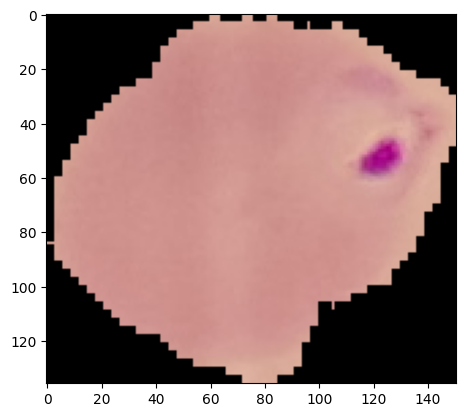

In [5]:
data_dir = '/data/cell_images_split'
train_path = data_dir + '/train'
val_path = data_dir + '/val'
test_path = data_dir + '/test'
subFolder = 'parasitized'
cell_images = os.listdir(os.path.join(train_path,subFolder))
#print name of first 2 images
print(cell_images[:2]) 
img_path = os.path.join(train_path,subFolder,cell_images[10]) 
#load image from file
img_bytes = tf.io.read_file(img_path) 
#image bytes to array and normlize the input [0,1]
img = tf.image.decode_image(img_bytes, channels=3, dtype=tf.float32) 
print("Images in directory:",len(cell_images)) 
print("Image shape:",img.shape)
plt.imshow(img)

Mean Height/Width: 134.35371495962985 133.62460310260366


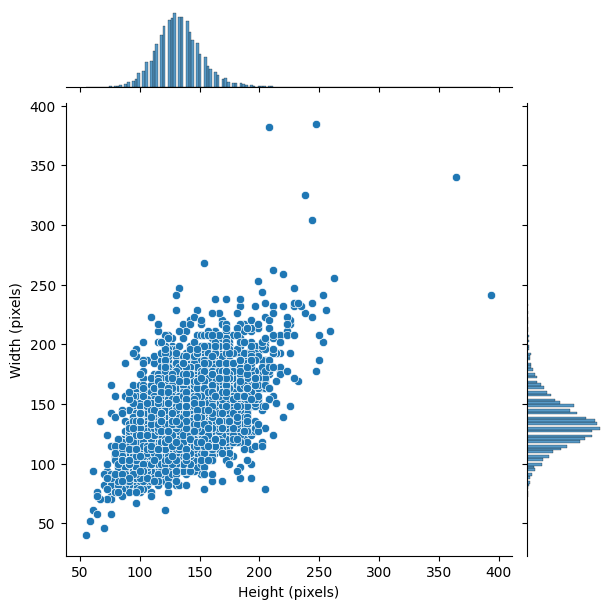

In [6]:
all_h = []
all_w = []
for img_name in cell_images:
    img_path = os.path.join(train_path, subFolder, img_name)
    image_bytes = tf.io.read_file(img_path) #load img from filesystem
    if not ('.png' in img_path): #only use png images
        continue
    image = tf.image.decode_image(image_bytes, channels=3, dtype=tf.float32)    
    h, w, rgb = image.shape  # tensor shape is (height, width, channels)
    all_h.append(h)  # image height
    all_w.append(w)  # image width

print("Mean Height/Width:",np.mean(all_h),np.mean(all_w)) 
#plot pixel width and height of all images in train set
plot = sns.jointplot(x=all_w, y=all_h) 
plot.set_axis_labels('Height (pixels)', 'Width (pixels)')

### Data augmentation

In [8]:
# dataset augmenntation generator for train and validation sets
train_val_generator = ImageDataGenerator(rotation_range=50,
                               width_shift_range=0.1,
                               height_shift_range=0.1,                  
                               zoom_range=0.1, 
                               horizontal_flip=True,
                               shear_range=0.05,
                               fill_mode='nearest')

train_val_generator.flow_from_directory(train_path)
train_val_generator.flow_from_directory(val_path)
ImageDataGenerator().flow_from_directory(test_path)

Found 22046 images belonging to 2 classes.
Found 2756 images belonging to 2 classes.
Found 2756 images belonging to 2 classes.


## Model Development

### Training Process

In [218]:
#hyperparameters
epochs = 10
fc_nodes= 64 
batch_size= 32  
dropout = 0.25  
stop_patience = 3

#stop training if val_loss does not decrease
stop = EarlyStopping(monitor='val_loss',patience=stop_patience)
#include parameters used in model name for saving
model_name = f"malariaNet-ep-{epochs}-fc-{fc_nodes}-do-{dropout}-bs-{batch_size}"

train_set = train_val_generator.flow_from_directory(train_path,
                                         target_size=(130,130),
                                         batch_size=batch_size,
                                         color_mode='rgb',
                                         class_mode='binary',
                                         shuffle=True)

val_set = train_val_generator.flow_from_directory(val_path,
                                         target_size=(130,130),
                                         batch_size=batch_size,
                                         color_mode='rgb',
                                         class_mode='binary',
                                         shuffle=False)

test_set = ImageDataGenerator().flow_from_directory(test_path,
                                         target_size=(130,130),
                                         batch_size=batch_size,
                                         color_mode='rgb',
                                         class_mode='binary',
                                         shuffle=False)

Found 22046 images belonging to 2 classes.
Found 2756 images belonging to 2 classes.
Found 2756 images belonging to 2 classes.


In [128]:
model = Sequential()

#layer 1,2
model.add(Conv2D(input_shape=(130,130,3), filters=16, kernel_size=(3,3), padding="same", activation="relu"))
model.add(Conv2D(filters=16, kernel_size=(3,3), padding="same", activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))

#layer 2,3
model.add(Conv2D(filters=32, kernel_size=(3,3), padding="same", activation="relu"))
model.add(Conv2D(filters=32, kernel_size=(3,3), padding="same", activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))

#layer 4,5,6
model.add(Conv2D(filters=64, kernel_size=(3,3), padding="same", activation="relu"))
model.add(Conv2D(filters=64, kernel_size=(3,3), padding="same", activation="relu"))
model.add(Conv2D(filters=64, kernel_size=(3,3), padding="same", activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))

#layer 7,8,9
model.add(Flatten())
model.add(Dense(units=fc_nodes, activation="relu")) 
model.add(Dropout(dropout))
model.add(Dense(units=1, activation="sigmoid"))

model.compile(loss='binary_crossentropy', optimizer='adam', metrics='accuracy')
model.summary()

Model: "sequential_7"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_47 (Conv2D)          (None, 130, 130, 16)      448       
                                                                 
 conv2d_48 (Conv2D)          (None, 130, 130, 16)      2320      
                                                                 
 max_pooling2d_20 (MaxPooli  (None, 65, 65, 16)        0         
 ng2D)                                                           
                                                                 
 conv2d_49 (Conv2D)          (None, 65, 65, 32)        4640      
                                                                 
 conv2d_50 (Conv2D)          (None, 65, 65, 32)        9248      
                                                                 
 max_pooling2d_21 (MaxPooli  (None, 32, 32, 32)        0         
 ng2D)                                                

In [129]:
model.fit(train_set, validation_data=val_set, epochs=epochs, callbacks=[stop])

Epoch 1/10
689/689 [==============================] - 277s 400ms/step - loss: 0.7763 - accuracy: 0.5601 - val_loss: 0.4963 - val_accuracy: 0.8280
Epoch 2/10
689/689 [==============================] - 283s 409ms/step - loss: 0.2634 - accuracy: 0.9145 - val_loss: 0.1752 - val_accuracy: 0.9448
Epoch 3/10
689/689 [==============================] - 318s 461ms/step - loss: 0.1839 - accuracy: 0.9434 - val_loss: 0.1519 - val_accuracy: 0.9496
Epoch 4/10
689/689 [==============================] - 320s 464ms/step - loss: 0.1746 - accuracy: 0.9471 - val_loss: 0.1604 - val_accuracy: 0.9485
Epoch 5/10
689/689 [==============================] - 310s 450ms/step - loss: 0.1613 - accuracy: 0.9495 - val_loss: 0.1484 - val_accuracy: 0.9499
Epoch 6/10
689/689 [==============================] - 314s 456ms/step - loss: 0.1632 - accuracy: 0.9488 - val_loss: 0.1458 - val_accuracy: 0.9536
Epoch 7/10
689/689 [==============================] - 313s 455ms/step - loss: 0.1614 - accuracy: 0.9493 - val_loss: 0.1482 -

### Model evaluation / set predictions?!

In [219]:
# 1. Accuracy and loss for val and 
metrics = pd.DataFrame(model.history.history)

<Axes: >

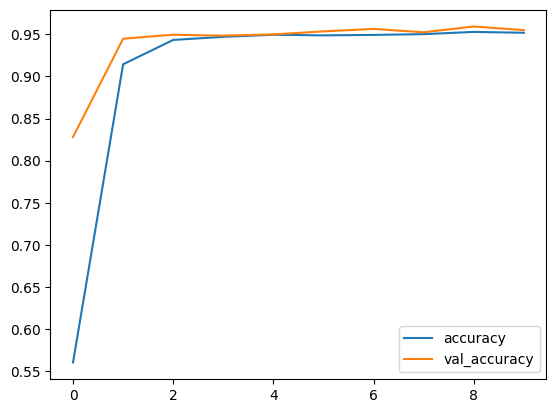

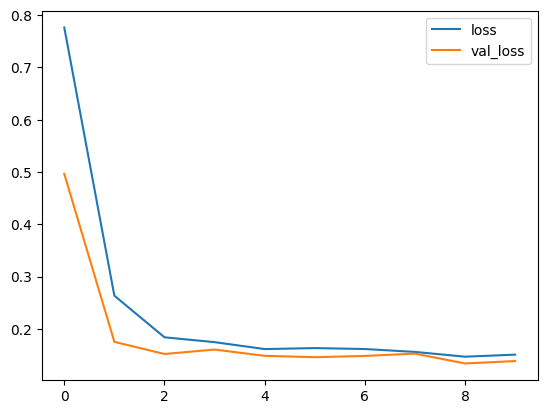

In [132]:
#accuracy for train and validation sets
metrics[['accuracy','val_accuracy']].plot()
#loss function for train and validation sets
metrics[['loss','val_loss']].plot() 

In [136]:
train_set_eval = model.evaluate(train_set)
val_set_eval   = model.evaluate(val_set)
test_set_eval  = model.evaluate(test_set)

87/87 [==============================] - 13s 148ms/step - loss: 0.1346 - accuracy: 0.9561


In [178]:
print('Train set Accuracy:',f'     {train_set_eval[1]*100:.2f}%')
print('Validation set Accuracy:',f'{val_set_eval[1]*100:.2f}%')
print('Test set Accuracy:',f'      {test_set_eval[1]*100:.2f}%')

Train set Accuracy:      95.12%
Validation set Accuracy: 95.21%
Test set Accuracy:       95.61%


In [186]:
test_predictions = model.predict(test_set)

87/87 [==============================] - 13s 143ms/step


In [214]:
print(len(test_predictions))
print(test_set.class_indices)
print(test_set.classes)
print(len(test_set.classes))
#predicted_value > 0.5 = uninfected
#predicted_value > 0.5 = parasitized
test_predictions[:3]

2756
{'parasitized': 0, 'uninfected': 1}
[0 0 0 ... 1 1 1]
2756


array([[0.03815119],
       [0.00652611],
       [0.00271597]], dtype=float32)

In [188]:
from sklearn.metrics import classification_report,confusion_matrix
print(classification_report(test_set.classes, predictions > 0.5))
#confusion_matrix(y_true, y_pred)
confusion_matrix(test_set.classes,predictions > 0.5)

# from sklearn.metrics import confusion_matrix
# import seaborn as sns
# import matplotlib.pyplot as plt

# conf_matrix = confusion_matrix(y_true, y_pred)

# plt.figure(figsize=(10, 7))
# sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
# plt.xlabel('Predicted Labels')
# plt.ylabel('True Labels')
# plt.title('Confusion Matrix')
# plt.show()


              precision    recall  f1-score   support

           0       0.96      0.95      0.96      1378
           1       0.95      0.96      0.96      1378

    accuracy                           0.96      2756
   macro avg       0.96      0.96      0.96      2756
weighted avg       0.96      0.96      0.96      2756



array([[1315,   63],
       [  58, 1320]])

In [193]:
metrics.to_excel('/models/'+ model_name + f'-test_acc-{test_set_eval[1]*100:.2f}' +'.xlsx', index=False)
model.save('/models/'+ model_name + f'-test_acc-{test_set_eval[1]*100:.2f}' +'.keras')

#### Model load and sample testing

In [216]:
model_path   = '/models/'
history_path = '/models/'
loaded_history = pd.read_excel('/models/'+ model_name + f'-test_acc-{test_set_eval[1]*100:.2f}' +'.xlsx')
loaded_model  = load_model('/models/'+ model_name + f'-test_acc-{test_set_eval[1]*100:.2f}' +'.keras')
#loaded_model.summary()
#loaded_history

1/1 [==============================] - 0s 199ms/step
['healthy(1).png', 'healthy(10).png', 'healthy(2).png', 'healthy(3).png', 'healthy(4).png', 'healthy(5).png', 'healthy(6).png', 'healthy(7).png', 'healthy(8).png', 'healthy(9).png', 'para(1).png', 'para(10).png', 'para(11).png', 'para(12).png', 'para(2).png', 'para(3).png', 'para(4).png', 'para(5).png', 'para(6).png', 'para(7).png', 'para(8).png', 'para(9).png']
/data/mixed-test/para(11).png
22
[[0.00012165]]
[0.00012165]
0.00012165018


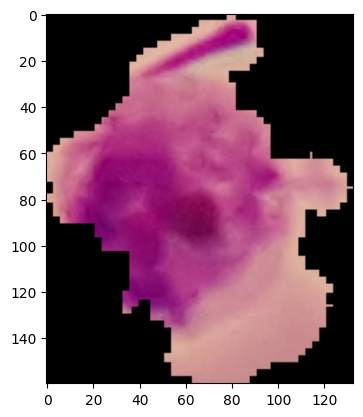

In [196]:
# Code to test againt real images and simulate Flask code
def load_image_bytes(bytes):
    img = tf.image.decode_image(bytes, channels=3)
    img = tf.image.resize(img, (130 , 130))
    img = img[tf.newaxis, :]
    return img

index= 12
test_images = os.listdir('/data/mixed-test')
prediction = model.predict(imgForModel)     
imgForModel= load_image_bytes(tf.io.read_file(os.path.join('/data/mixed-test',test_images[index])))
print(test_images)
print(os.path.join('/data/mixed-test',test_images[index]))
print(len(test_images))

image_bytes = tf.io.read_file(os.path.join('/data/mixed-test',test_images[index]))
image_print = tf.image.decode_image(image_bytes, channels=3, dtype=tf.float32) 
#image bytes to array and normlize the input [0,1]

print(prediction)
print(prediction[0])
print(prediction[0][0])
plt.imshow(image_print)